14.60% of values between [3 , 1000]
8.499472
3.0 505.5


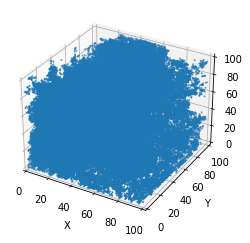

In [8]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.colors as mcolors
from matplotlib.colors import LogNorm
#import cupy as cp
import random
import trimesh
import trimesh.voxel as vox
import torch
from packaging import version as pver
# load data from file

#density = np.load('/home/zep/Desktop/repos/density_for.npy')
#density = np.load('/home/zep/Desktop/repos/density.npy')
density = np.load('/home/daniele/dev/3DReconstruction/torch-ngp/results/6angles/TV_1e-13/density_TV1e-13.npy')


# Create voxel grid from 3D density array
density_torch = torch.tensor(density, device='cuda')

'''

low_b = 0
for bound in [3.5,10,100,250,500,np.max(density)]:
    
    up_b = bound 
    flat_data = density[np.logical_and (density < up_b, density> low_b)].flatten()

    # Create boxplot
    fig, ax = plt.subplots()
    ax.boxplot(flat_data)

    # Add histogram with same x-axis
    hist_bins = np.linspace(np.min(flat_data), np.max(flat_data), num=15)
    values, bins, patches = ax.hist(
                            flat_data, 
                            bins=hist_bins, 
                            alpha=0.5,
                            edgecolor='black')

    # Add labels
    ax.set_xlabel('Values')
    ax.set_ylabel('Frequency')

    # Set xticks to middle of each bin with label for start and end of each bin
    bin_sizes = np.diff(bins)
    bin_centers = bins[:-1] + bin_sizes / 2
    for i in range(len(bin_sizes)):
        ax.text(bin_centers[i], values[i], f"{bins[i]:.2f}\n{bins[i+1]:.2f}", ha="center")
    plt.xticks(bin_centers, ['' for b in bin_sizes]) # hide bin centers
    plt.xlim([bins[0], bins[-1]])
    plt.savefig(f"bin_{low_b}_{up_b}.jpg")

    low_b = bound
'''

# set treshold
'''
density[:,:,95:] = 0
density[:,95:,:] = 0
density[95:,:,:] = 0
density[:,:,:5] = 0
density[:,:5,:] = 0
density[:5,:,:] = 0'''
#density[:,:,:]=0
threshold = 3
upper = 1000
# create mask for values above threshold


mask = np.logical_and(density >= threshold ,density < upper)
# set values below threshold to NaN


mask_t =   torch.from_numpy(np.logical_and(density > threshold ,density < upper))

coordinates = torch.nonzero(mask_t)

vertices = coordinates.cpu().numpy()
faces = []
for i in range(vertices.shape[0]):
    faces.append([i, i, i])

mesh = trimesh.Trimesh(vertices=vertices, faces=faces)


#mesh.export('/home/zep/Desktop/datasets/street/torch-ngp-results/fox/non_zero_values.ply')


density[~mask] = np.nan

'''
density_zero = density
density_zero[~mask] = 0
for i in range(10):
    ray_x = density_zero[0:100, i*10, 10]
    plt.plot(ray_x,color = 'red',linewidth=.5,linestyle ='dotted' )
for i in range(10):
    ray_y = density_zero[i*10, 0:100 , 10]
    plt.plot(ray_y,color = 'blue',linewidth=.5,linestyle ='dotted' )
for i in range(10):
    ray_z = density_zero[i*10, 0:100 , 10]
    plt.plot(ray_z,color = 'green',linewidth=.5,linestyle ='dotted' )
plt.show()

'''

percent = np.count_nonzero(mask)/density.size * 100 
print(f'{percent:.2f}% of values between [{threshold} , {upper}]')

print(np.mean(density[mask]))
# create x, y, z coordinate arrays
x, y, z = np.meshgrid(np.arange(density.shape[0]), 
                      np.arange(density.shape[1]), 
                      np.arange(density.shape[2]))

# create figure and 3D axis
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# colormap for visualizing densities
low_color = mcolors.CSS4_COLORS['yellow']
high_color = mcolors.CSS4_COLORS['red']
sizes = 10 * density[mask].flatten() / np.nanmax(density)

#norm=LogNorm(vmin=np.min(density[mask]), vmax=np.max(density[mask]))
norm= plt.Normalize(vmin=np.min(density[mask]), vmax=np.max(density[mask]))
#sm = plt.cm.ScalarMappable(cmap = plt.cm.jet,norm = norm ) # to get color porpotional to denisty values
print(np.min(density[mask]), np.max(density[mask]))

# Set normalization for colormap
norm = plt.Normalize(vmin=np.min(np.asarray(x[mask])), vmax=np.max(np.asarray(x[mask])))


# Create colormap
cmap = plt.cm.get_cmap('gist_gray')
# Set color array based on x-coordinate
color = cmap(norm(np.asarray(z[mask])))
# create scatter plot
#ax.scatter(x[mask].get().tolis, y[mask].get(), z[mask].get(), s=1, c=sm.to_rgba(density[mask]))
ax.scatter(x[mask].tolist(), y[mask].tolist(), z[mask].tolist(), s=1)#, c=color)#, c=sm.to_rgba(density[mask]).tolist())

# set limits and labels
ax.set_xlim([0, density.shape[0]])
ax.set_ylim([0, density.shape[1]])
ax.set_zlim([0, density.shape[2]])
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
#cbar = plt.colorbar(cm, ax=ax)
#cbar.ax.set_ylabel('Desnity value')
# show plot
plt.show()
